# Analisis Data Produk Kemasan — Misi Bomori di Bumi
Pipeline: **Data Preparation → Data Understanding → Outlier → Visualisasi & Distribusi → Uji Hipotesis → Insight**.
Dataset: `food.csv` (produk makanan kemasan; kandungan gizi per 100 g). Taraf signifikansi $\alpha = 0{,}05$.

## 1. Data Preparation

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import math
from scipy import stats  

pd.set_option('display.float_format', '{:.4f}'.format); pd.set_option('display.width', 200)
ALPHA = 0.05
df = pd.read_csv('food.csv')

print(df.shape)
df.head()

(4758, 15)


,code,product_name,food_group,nutri_score,palm_oil,energy,fat,saturated_fat,carbohydrates,sugars,fiber,proteins,salt,additives_count,nutrition_score
0,3331935000030,Ulti,Beverages,E,No,184.0000,0.4000,0.2000,8.8000,7.3000,0.8000,0.8000,0.0200,0,11
1,7622210450319,Prince goût Chocolat,Sugary snacks,D,Yes,1955.0000,17.0000,5.7000,69.0000,32.0000,4.7000,6.3000,0.5000,4,14
2,3263851740991,Chili con carne (Pur bœuf),Composite foods,A,No,430.0000,2.8000,1.0000,11.9000,2.8000,1.0000,6.8000,0.8700,0,-1
3,3760020509514,Pulpe de tomate,Fruits and vegetables,A,No,86.0000,0.2000,0.0000,3.0000,3.0000,0.9000,1.2000,0.0100,1,-6
4,5410056190221,Déli Soup' Brocoli Ciboulette,Fruits and vegetables,B,No,108.0000,1.2000,0.7000,2.3000,0.9000,0.9000,1.0000,0.7200,2,2


In [ ]:
# Kualitas data: tipe, missing, duplikat, validitas logis
print(df.dtypes, '\n')

print('Missing per kolom:\n', df.isna().sum()[df.isna().sum() > 0], '(tidak ada missing)')
print('Duplikat baris:', df.duplicated().sum(), '| duplikat code:', df.code.duplicated().sum())
print('Nama produk sama (kode beda -> produk berbeda, dibiarkan):', df.product_name.duplicated().sum())
gram = ['fat','saturated_fat','carbohydrates','sugars','fiber','proteins','salt']
print('Nilai gizi negatif:', (df[gram] < 0).sum().sum(), '| > 100 g/100 g:', (df[gram] > 100).sum().sum())
print('Saturated fat > fat:', (df.saturated_fat > df.fat + 0.01).sum(), '| sugars > carbohydrates:', (df.sugars > df.carbohydrates + 0.01).sum())
print('Total fat+carb+protein+fiber > 100.5:', ((df.fat+df.carbohydrates+df.proteins+df.fiber) > 100.5).sum())
# Perbaikan kecil: salt mengandung artefak float (0.499999999999999) -> bulatkan; code hanya identitas -> string
df['code'] = df['code'].astype(str)
df[gram] = df[gram].round(4)
num_cols = ['energy','fat','saturated_fat','carbohydrates','sugars','fiber','proteins','salt','additives_count','nutrition_score']
cat_cols = ['food_group','nutri_score','palm_oil']

code                 int64
product_name        object
food_group          object
nutri_score         object
palm_oil            object
energy             float64
fat                float64
saturated_fat      float64
carbohydrates      float64
sugars             float64
fiber              float64
proteins           float64
salt               float64
additives_count      int64
nutrition_score      int64
dtype: object 

Missing per kolom:
 Series([], dtype: int64) (kosong = tidak ada missing)
Duplikat baris: 0 | duplikat code: 0
Nama produk sama (kode beda -> produk berbeda, dibiarkan): 254
Nilai gizi negatif: 0 | > 100 g/100 g: 0
Saturated fat > fat: 0 | sugars > carbohydrates: 0
Total fat+carb+protein+fiber > 100.5: 0


**Catatan persiapan:** tidak ada missing value maupun duplikat; semua nilai gizi valid secara logis. `code` hanya pengenal (bukan numerik analitik) dan `product_name` bersifat teks bebas sehingga keduanya tidak dianalisis sebagai fitur. Kolom numerik: 10 kolom di atas; kategorikal: `food_group`, `nutri_score`, `palm_oil`.

## 2. Fungsi Buatan Sendiri
Semua statistik dan statistik uji dihitung dengan fungsi di bawah; `scipy.stats` hanya dipakai untuk `cdf`/`sf`/`ppf`. Fungsi library (`describe`, `mean`, `skew`, `ttest_1samp`, dst.) hanya muncul di bagian pembanding (Bagian 8).

In [49]:
def f_mean(x): x = np.asarray(x, float); return x.sum() / len(x)
def f_var(x): x = np.asarray(x, float); m = f_mean(x); return ((x - m) ** 2).sum() / (len(x) - 1)   # sampel (n-1)
def f_std(x): return math.sqrt(f_var(x))
def f_quantile(x, q):                         # interpolasi linear (posisi (n-1)q)
    a = np.sort(np.asarray(x, float)); pos = (len(a) - 1) * q; lo = int(math.floor(pos)); hi = min(lo + 1, len(a) - 1)
    return a[lo] + (a[hi] - a[lo]) * (pos - lo)
def f_median(x): return f_quantile(x, .5)
def f_mode(x):
    v, c = np.unique(np.asarray(x), return_counts=True); return v[c.argmax()]       # nilai terkecil bila seri
def f_skew(x):                                # Fisher-Pearson terkoreksi (G1)
    x = np.asarray(x, float); n = len(x); m = f_mean(x); m2 = ((x - m) ** 2).sum() / n; m3 = ((x - m) ** 3).sum() / n
    return math.sqrt(n * (n - 1)) / (n - 2) * m3 / m2 ** 1.5
def f_kurt(x):                                # excess kurtosis terkoreksi (G2)
    x = np.asarray(x, float); n = len(x); m = f_mean(x); m2 = ((x - m) ** 2).sum() / n; m4 = ((x - m) ** 4).sum() / n
    g2 = m4 / m2 ** 2 - 3
    return (n - 1) / ((n - 2) * (n - 3)) * ((n + 1) * g2 + 6)
def f_freq(x):
    d = {}
    for v in x: d[v] = d.get(v, 0) + 1
    t = pd.DataFrame({'frekuensi': pd.Series(d)}).sort_values('frekuensi', ascending=False)
    t['persen (%)'] = t.frekuensi / t.frekuensi.sum() * 100; return t
def f_peaks(counts, frac=.10):                # puncak: maksimum lokal histogram terhaluskan, dipisah lembah >= frac
    sm = np.convolve(np.r_[0, counts, 0], np.ones(3) / 3, mode='same')[1:-1]; top = sm.max(); keep = []
    for i in range(len(sm)):
        l = sm[i - 1] if i > 0 else 0; r = sm[i + 1] if i < len(sm) - 1 else 0
        if sm[i] > l and sm[i] >= r and sm[i] >= frac * top:
            if keep and sm[keep[-1]:i + 1].min() > (1 - frac) * min(sm[keep[-1]], sm[i]):
                if sm[i] > sm[keep[-1]]: keep[-1] = i
            else: keep.append(i)
    return len(keep)
# --- statistik uji (p-value lewat cdf / sf) ---
def p_t(t, db, alt): return {'two': 2 * stats.t.sf(abs(t), db), 'less': stats.t.cdf(t, db), 'greater': stats.t.sf(t, db)}[alt]
def p_z(z, alt): return {'two': 2 * stats.norm.sf(abs(z)), 'less': stats.norm.cdf(z), 'greater': stats.norm.sf(z)}[alt]
def t_satu_sampel(x, mu0, alt):
    n = len(x); t = (f_mean(x) - mu0) / (f_std(x) / math.sqrt(n)); return t, p_t(t, n - 1, alt)
def t_welch(a, b, d0, alt):                   # H0: mu_a - mu_b = d0
    va, vb, na, nb = f_var(a), f_var(b), len(a), len(b); se2 = va / na + vb / nb
    t = (f_mean(a) - f_mean(b) - d0) / math.sqrt(se2)
    db = se2 ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1)); return t, p_t(t, db, alt), db
def z_prop_satu(x, n, p0, alt):
    z = (x / n - p0) / math.sqrt(p0 * (1 - p0) / n); return z, p_z(z, alt)
def z_prop_dua(x1, n1, x2, n2, alt):
    pp = (x1 + x2) / (n1 + n2); z = (x1 / n1 - x2 / n2) / math.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2)); return z, p_z(z, alt)
def chi2_var(x, s0, alt):
    n = len(x); c = (n - 1) * f_var(x) / s0 ** 2
    return c, {'greater': stats.chi2.sf(c, n - 1), 'less': stats.chi2.cdf(c, n - 1), 'two': 2 * min(stats.chi2.cdf(c, n - 1), stats.chi2.sf(c, n - 1))}[alt]
def f_var_test(a, b):                         # dua sisi
    F = f_var(a) / f_var(b); d1, d2 = len(a) - 1, len(b) - 1
    return F, 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))

## 3. Data Understanding — Soal 1: Statistik Deskriptif

In [50]:
def desc(x):
    q1, q2, q3 = f_quantile(x, .25), f_quantile(x, .5), f_quantile(x, .75)
    return pd.Series({'mean': f_mean(x), 'median': f_median(x), 'modus': f_mode(x), 'std (sampel)': f_std(x),
        'var (sampel)': f_var(x), 'range': x.max() - x.min(), 'min': x.min(), 'max': x.max(),
        'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': q3 - q1, 'skewness': f_skew(x), 'excess kurtosis': f_kurt(x)})
desc_tbl = df[num_cols].apply(desc).T
desc_tbl

,mean,median,modus,std (sampel),var (sampel),range,min,max,Q1,Q2,Q3,IQR,skewness,excess kurtosis
energy,1049.8888,907.5000,0.0000,816.7276,667044.0170,3766.0000,0.0000,3766.0000,301.0000,907.5000,1632.7500,1331.7500,0.6865,-0.1385
fat,11.7898,4.3000,0.0000,17.5134,306.7178,100.0000,0.0000,100.0000,0.5000,4.3000,16.7000,16.2000,2.6018,8.1171
saturated_fat,4.3278,1.1000,0.0000,8.0783,65.2590,94.0000,0.0000,94.0000,0.1000,1.1000,5.0000,4.9000,4.6902,34.0973
carbohydrates,28.3450,14.5000,0.0000,27.0719,732.8871,100.0000,0.0000,100.0000,5.3000,14.5000,54.7750,49.4750,0.6493,-1.0920
sugars,12.4412,4.5250,0.0000,17.3934,302.5313,100.0000,0.0000,100.0000,1.4000,4.5250,15.8500,14.4500,2.0674,4.2409
fiber,2.5341,1.5000,0.0000,3.6416,13.2614,75.0000,0.0000,75.0000,0.2000,1.5000,3.4000,3.2000,5.2252,58.9451
proteins,6.6204,5.4000,0.0000,6.7932,46.1471,81.9000,0.0000,81.9000,1.0000,5.4000,9.1000,8.1000,1.9265,7.6025
salt,0.7013,0.4000,0.0000,1.3555,1.8373,57.0000,0.0000,57.0000,0.0300,0.4000,1.0000,0.9700,18.1675,653.0892
additives_count,1.7806,1.0000,0.0000,2.4046,5.7820,21.0000,0.0000,21.0000,0.0000,1.0000,3.0000,3.0000,2.0617,5.8547
nutrition_score,6.4641,5.0000,0.0000,8.7760,77.0173,48.0000,-13.0000,35.0000,0.0000,5.0000,13.0000,13.0000,0.2906,-0.8354


In [51]:
for c in cat_cols:
    t = f_freq(df[c]).round(2)
    print(f'--- {c} ---'); display(t)

--- food_group ---


,frekuensi,persen (%)
Sugary snacks,816,17.1500
Cereals and potatoes,775,16.2900
Beverages,710,14.9200
Composite foods,609,12.8000
Fruits and vegetables,501,10.5300
Milk and dairy products,462,9.7100
Fat and sauces,337,7.0800
Fish meat eggs,331,6.9600
Salty snacks,217,4.5600


--- nutri_score ---


,frekuensi,persen (%)
A,1161,24.4000
D,1088,22.8700
C,1018,21.4000
E,762,16.0200
B,729,15.3200


--- palm_oil ---


,frekuensi,persen (%)
No,4402,92.5200
Yes,356,7.4800


Skewness/kurtosis memakai estimator sampel (G1 dan G2, bias-corrected); kurtosis yang dilaporkan adalah *excess* (normal = 0).

### 💡 Insight Soal 1 — Statistik deskriptif
- **Semua variabel gizi miring kanan: mean jauh di atas median.** Gula mean 12,44 vs median 4,53; lemak 11,79 vs 4,30; lemak jenuh 4,33 vs 1,10; garam 0,70 vs 0,40; serat 2,53 vs 1,50. Produk "tipikal" jauh lebih rendah gizinya daripada rata-rata; rata-rata ditarik oleh segelintir produk pekat (minyak, gula, bumbu).
- **Modus = 0 untuk semua kolom**: banyak produk bernilai nol (mis. minuman tanpa lemak/serat, produk tanpa aditif).
- **Garam paling ekstrem**: skewness 18,2 dan excess kurtosis 653 (max 57 g vs Q3 hanya 1,0 g). Saturated fat dan serat juga berekor sangat berat (skewness 4,7 dan 5,2).
- **Energi dan karbohidrat relatif lebih simetris** (skewness ≈ 0,65–0,69) tetapi sangat lebar (energi 0–3.766 kJ, IQR 1.332; karbohidrat IQR 49,5). `nutrition_score` berkisar −13 s.d. 35 dengan median 5.
- **Kategori:** *Sugary snacks* terbanyak (17,15%), lalu *Cereals and potatoes* (16,29%) dan *Beverages* (14,92%); *Salty snacks* paling sedikit (4,56%). Nutri-Score hampir merata: A 24,4%, D 22,9%, C 21,4%, E 16,0%, B 15,3%. Hanya **7,48%** produk memakai minyak sawit.

## 3. Soal 2 — Identifikasi & Penanganan Outlier

In [52]:
# Metode: aturan Tukey (IQR). Outlier jika x < Q1 - 1.5*IQR atau x > Q3 + 1.5*IQR
def iqr_bounds(s):
    q1, q3 = f_quantile(s, .25), f_quantile(s, .75); i = q3 - q1
    return q1 - 1.5*i, q3 + 1.5*i
rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df[c]); n_lo, n_hi = (df[c] < lo).sum(), (df[c] > hi).sum()
    rows.append([c, lo, hi, n_lo, n_hi, n_lo+n_hi, (n_lo+n_hi)/len(df)*100])
out_tbl = pd.DataFrame(rows, columns=['kolom','batas bawah','batas atas','outlier rendah','outlier tinggi','total','persen (%)']).set_index('kolom')
out_tbl

,batas bawah,batas atas,outlier rendah,outlier tinggi,total,persen (%)
kolom,,,,,,
energy,-1696.6250,3630.3750,0,35,35,0.7356
fat,-23.8000,41.0000,0,257,257,5.4014
saturated_fat,-7.2500,12.3500,0,559,559,11.7486
carbohydrates,-68.9125,128.9875,0,0,0,0.0000
sugars,-20.2750,37.5250,0,475,475,9.9832
fiber,-4.6000,8.2000,0,266,266,5.5906
proteins,-11.1500,21.2500,0,224,224,4.7079
salt,-1.4250,2.4550,0,166,166,3.4889
additives_count,-4.5000,7.5000,0,166,166,3.4889


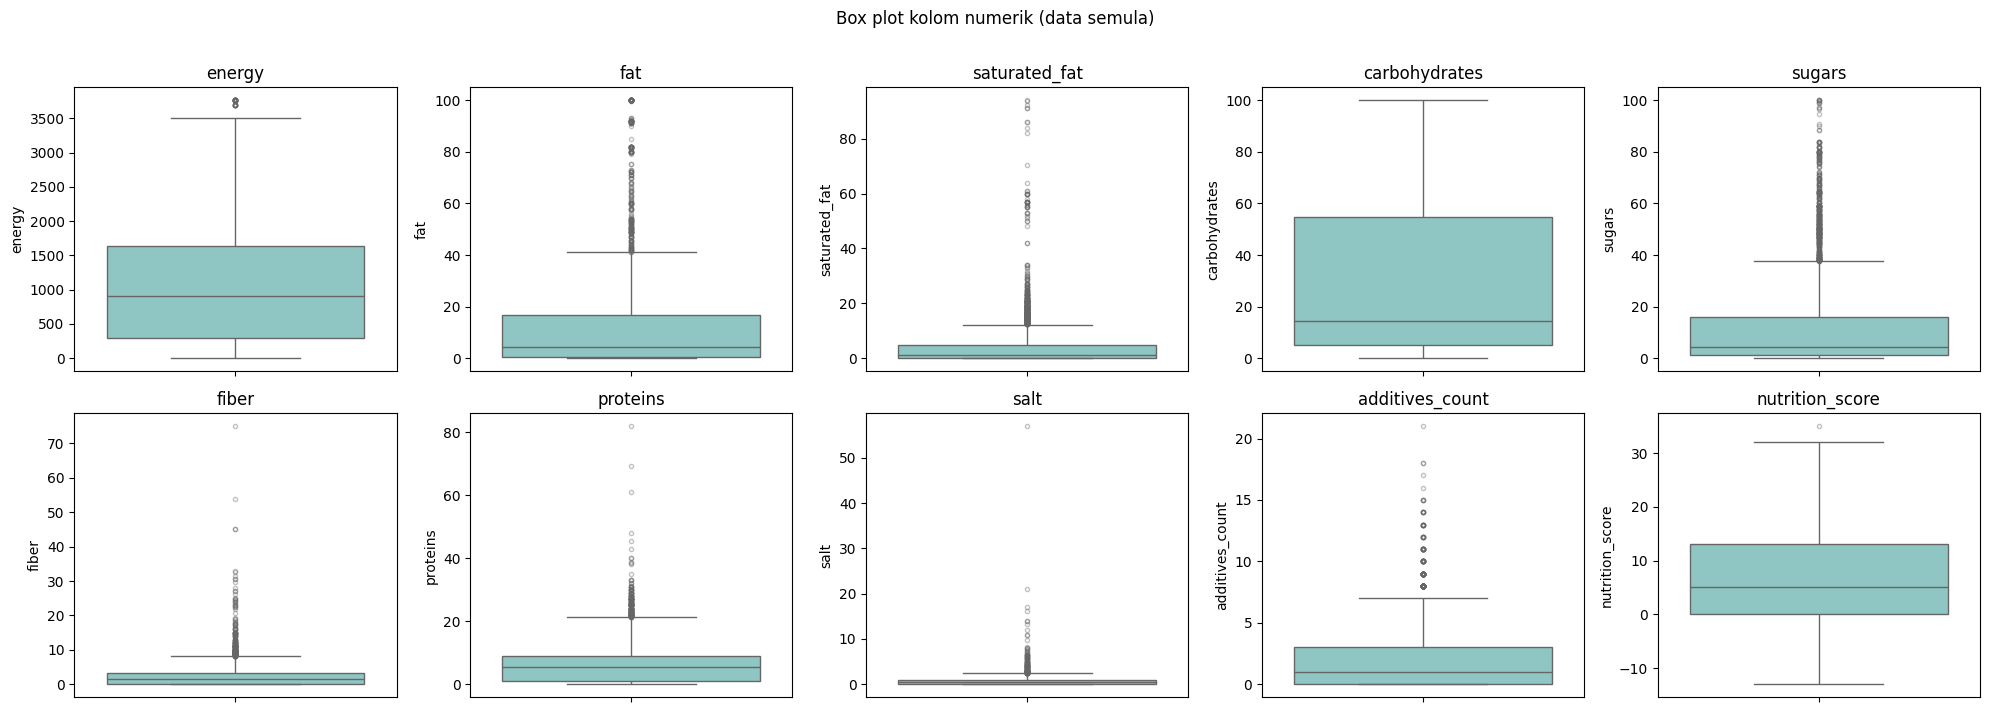

In [53]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color='#86cecb', flierprops=dict(marker='o', markersize=3, alpha=.4)); ax.set_title(c)
plt.suptitle('Box plot kolom numerik (data semula)', y=1.01); plt.tight_layout(); plt.show()

In [54]:
# Cek apakah outlier "nyata" atau galat data: produk dengan nilai paling ekstrem
for c in ['salt','fat','energy','saturated_fat','sugars']:
    display(df.nlargest(3, c)[['product_name','food_group',c]])

,product_name,food_group,salt
4547,Bouillon (poulet),Milk and dairy products,57.0000
3412,Viandox,Fat and sauces,21.0058
4480,Log Cabin,Cereals and potatoes,17.0000


,product_name,food_group,fat
122,Huilve vierge de noix,Fat and sauces,100.0000
501,"Nature Bio - Mélange 4 Huiles : Colza, Olive, ...",Fat and sauces,100.0000
503,Mélange 5 Huiles Enfants Bio - 250ML - Quintesens,Fat and sauces,100.0000


,product_name,food_group,energy
501,"Nature Bio - Mélange 4 Huiles : Colza, Olive, ...",Fat and sauces,3766.0000
503,Mélange 5 Huiles Enfants Bio - 250ML - Quintesens,Fat and sauces,3766.0000
612,Huile de colza,Fat and sauces,3766.0000


,product_name,food_group,saturated_fat
2972,Extra Virgin Raw Coconut Oil,Fat and sauces,94.0000
1886,Aceite De Coco Virgen Eco Veritas 270ML,Fat and sauces,93.9000
3586,Huile De Coco Bio - 325 ML - Amanprana,Fat and sauces,92.1000


,product_name,food_group,sugars
958,Sucre en poudre,Sugary snacks,100.0000
1018,Sucre de canne,Sugary snacks,100.0000
2556,Sucre en poudre,Sugary snacks,100.0000


In [55]:
# Keputusan: hapus HANYA nilai yang mustahil secara domain; nilai ekstrem yang valid dipertahankan.
invalid = ((df[gram] < 0) | (df[gram] > 100)).any(axis=1) | (df.saturated_fat > df.fat + 0.01) | (df.sugars > df.carbohydrates + 0.01) \
          | ((df.fat + df.carbohydrates + df.proteins + df.fiber) > 100.5) | (df.energy < 0) | (df.additives_count < 0)
print('Baris mustahil yang dihapus:', invalid.sum())
df_outlier_v2 = df.loc[~invalid].reset_index(drop=True)
print('df_outlier_v2:', df_outlier_v2.shape)

Baris mustahil yang dihapus: 0
df_outlier_v2: (4758, 15)


**Metode:** aturan IQR Tukey (1,5×IQR) + box plot, dilengkapi pemeriksaan validitas domain (nilai ≤ 100 g/100 g, lemak jenuh ≤ lemak, gula ≤ karbohidrat, total makronutrien ≤ 100).

**Keputusan: tidak ada baris dibuang/di-winsorize; `df_outlier_v2` identik dengan data semula.** Alasan:
1. Outlier menurut IQR banyak ditemukan karena distribusi gizi pangan memang miring kanan dan beragam antar-kelompok (minyak/saus, camilan manis, keju, dll. wajar bernilai tinggi pada lemak, gula, garam, energi).
2. Pemeriksaan validitas menunjukkan **tidak ada nilai mustahil**; produk ekstrem teratas adalah produk yang secara kategori masuk akal (mis. minyak ≈ 100 g lemak, garam/bumbu pekat).
3. Menghapus/memotong nilai valid akan membiaskan rata-rata, variansi, dan proporsi yang justru menjadi sasaran uji hipotesis Soal 5–6, serta menghilangkan produk nyata dari populasi.
4. Ukuran sampel besar (n ≈ 4,7 ribu) sehingga uji-t robust terhadap kemiringan (CLT); uji variansi (5.4, 6.4) bergantung pada normalitas — keterbatasan ini dicatat pada bagian hipotesis.

### 💡 Insight Soal 2 — Outlier
- Outlier IQR hanya berada di **sisi atas**. Terbanyak: lemak jenuh **11,7%** (559 produk), gula **10,0%** (475), serat 5,6%, lemak 5,4%, protein 4,7%, garam 3,5%, aditif 3,5%; energi 0,7%; `nutrition_score` 1 produk; karbohidrat **tidak ada**.
- Banyaknya "outlier" bukan galat, melainkan **ciri campuran kelompok pangan**: minyak (lemak 100 g, lemak jenuh hingga 94 g pada minyak kelapa), gula pasir (gula 100 g), bumbu/kaldu (garam tinggi).
- **Satu temuan perlu dicatat:** produk "Bouillon (poulet)" bergaram 57 g/100 g tercatat di kelompok *Milk and dairy products* (kemungkinan salah kategori/entri). Hanya 1 dari 4.758 baris, dampaknya pada rata-rata garam < 0,012 g, sehingga kesimpulan tidak berubah. Maka keputusan: data tidak diubah (`df_outlier_v2` = data semula).

## 4. Soal 3 — Histogram & Bar Chart

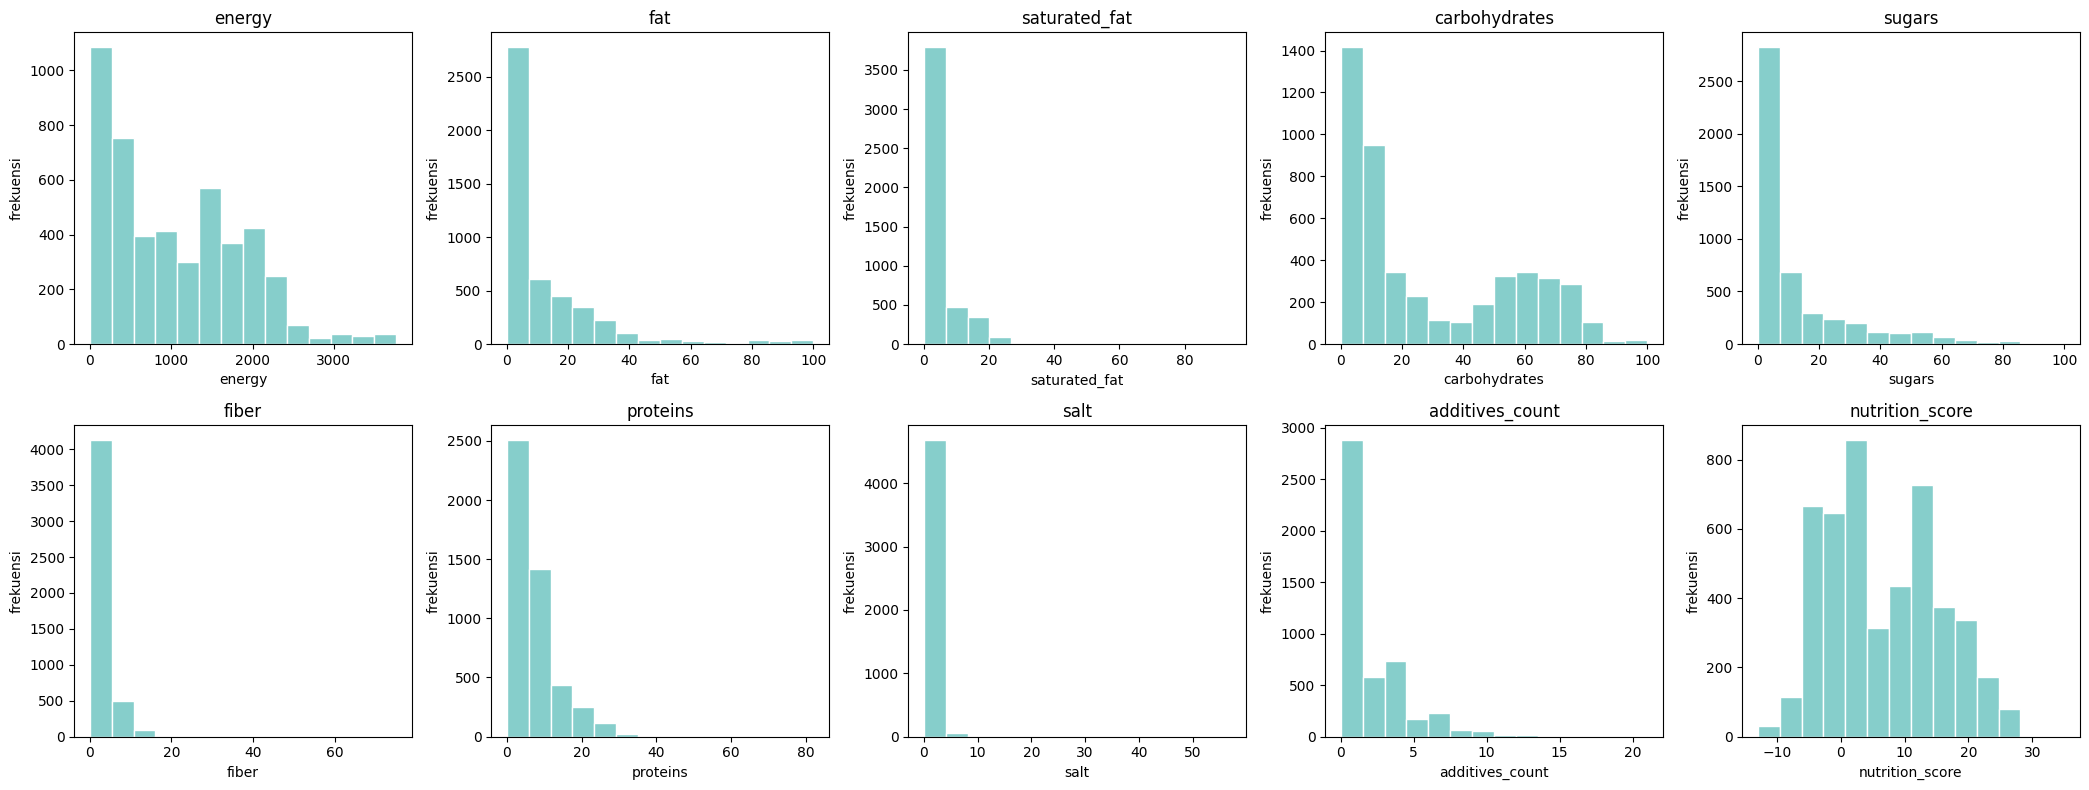

energy           rentang nilai: 0.00 - 3766.00 | lebar interval 269.00 | interval tertinggi [0.00, 269.00) dengan frekuensi 1085 (22.8%)
fat              rentang nilai: 0.00 - 100.00 | lebar interval 7.14 | interval tertinggi [0.00, 7.14) dengan frekuensi 2778 (58.4%)
saturated_fat    rentang nilai: 0.00 - 94.00 | lebar interval 6.71 | interval tertinggi [0.00, 6.71) dengan frekuensi 3789 (79.6%)
carbohydrates    rentang nilai: 0.00 - 100.00 | lebar interval 7.14 | interval tertinggi [0.00, 7.14) dengan frekuensi 1416 (29.8%)
sugars           rentang nilai: 0.00 - 100.00 | lebar interval 7.14 | interval tertinggi [0.00, 7.14) dengan frekuensi 2822 (59.3%)
fiber            rentang nilai: 0.00 - 75.00 | lebar interval 5.36 | interval tertinggi [0.00, 5.36) dengan frekuensi 4134 (86.9%)
proteins         rentang nilai: 0.00 - 81.90 | lebar interval 5.85 | interval tertinggi [0.00, 5.85) dengan frekuensi 2511 (52.8%)
salt             rentang nilai: 0.00 - 57.00 | lebar interval 4.07 | inter

In [56]:
df = df_outlier_v2   # data hasil penanganan dipakai untuk Soal 3-6
COLOR = '#86cecb'
fig, axes = plt.subplots(2, 5, figsize=(21, 8))
hist_info = {}
for ax, c in zip(axes.ravel(), num_cols):
    counts, edges, _ = ax.hist(df[c], bins='sturges', color=COLOR, edgecolor='white')
    k = counts.argmax(); hist_info[c] = (edges, counts, k)
    ax.set_title(c); ax.set_xlabel(c); ax.set_ylabel('frekuensi')
plt.tight_layout(); plt.show()
for c in num_cols:
    e, n, k = hist_info[c]
    print(f'{c:16s} rentang nilai: {df[c].min():.2f} - {df[c].max():.2f} | lebar interval {e[1]-e[0]:.2f} | '
          f'interval tertinggi [{e[k]:.2f}, {e[k+1]:.2f}) dengan frekuensi {int(n[k])} ({n[k]/len(df)*100:.1f}%)')

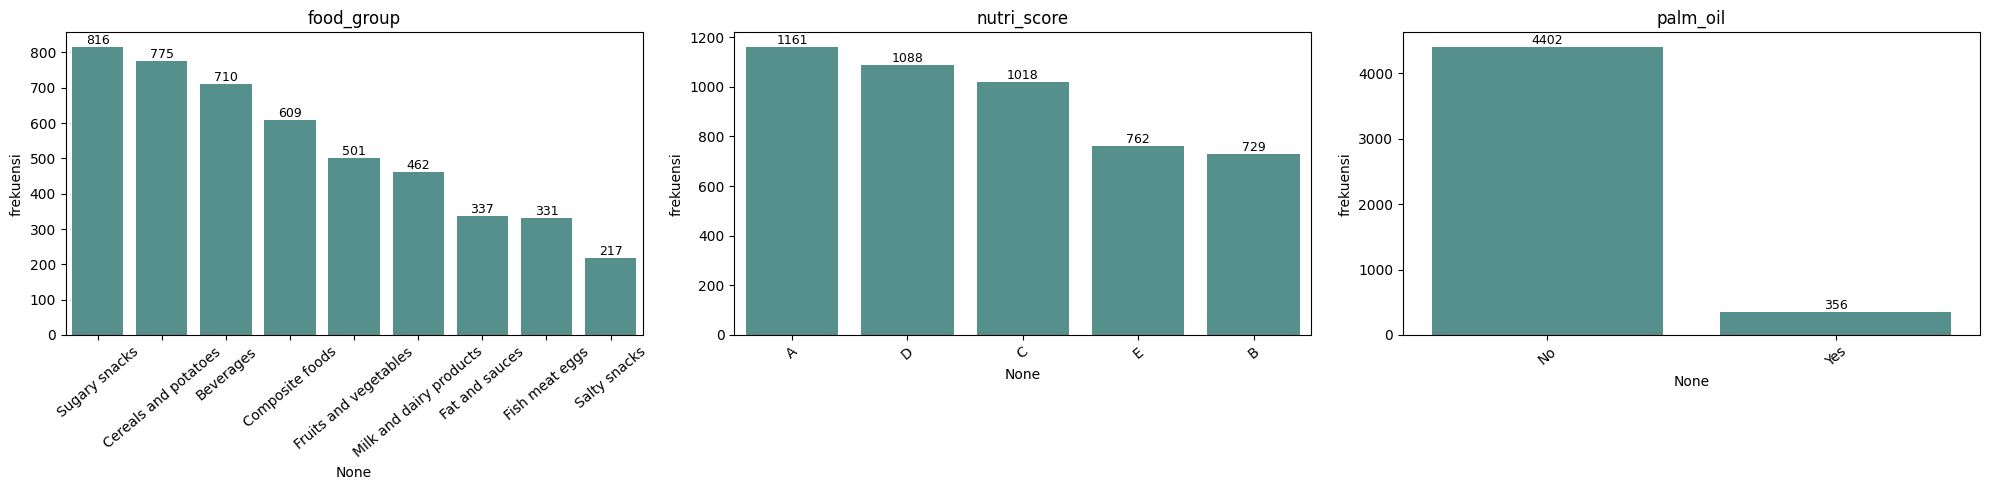

food_group   tertinggi: Sugary snacks (816 produk, 17.2%)
nutri_score  tertinggi: A (1161 produk, 24.4%)
palm_oil     tertinggi: No (4402 produk, 92.5%)


In [57]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, c in zip(axes, cat_cols):
    vc = f_freq(df[c]).frekuensi; sns.barplot(x=vc.index, y=vc.values, ax=ax, color='#4c9a96')
    ax.set_title(c); ax.set_ylabel('frekuensi'); ax.tick_params(axis='x', rotation=40)
    for i, v in enumerate(vc.values): ax.text(i, v, v, ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()
for c in cat_cols:
    vc = f_freq(df[c]).frekuensi; print(f'{c:12s} tertinggi: {vc.index[0]} ({vc.iloc[0]} produk, {vc.iloc[0]/len(df)*100:.1f}%)')

**Cara membaca:** keluaran di bawah grafik menyebut rentang nilai, interval (bin) dengan frekuensi tertinggi tiap histogram, dan kategori terbanyak tiap bar chart. Secara umum, hampir semua variabel gizi (lemak, lemak jenuh, gula, serat, protein, garam, aditif) memiliki bin tertinggi di dekat nilai terendah (ekor panjang ke kanan); `food_group` didominasi *Sugary snacks*, `nutri_score` terbanyak grade A, dan `palm_oil` didominasi "No".

### 💡 Insight Soal 3 — Histogram dan bar chart
- **Hampir semua histogram menumpuk di interval paling kiri (nilai terendah):** garam 98,5% produk di 0–4,07 g; serat 86,9% di 0–5,36 g; lemak jenuh 79,6% di 0–6,71 g; aditif 60,6% di 0–1,5; gula 59,3% di 0–7,14 g; lemak 58,4% di 0–7,14 g; protein 52,8% di 0–5,85 g.
- **Energi** (22,8% di 0–269 kJ) dan **karbohidrat** (29,8% di 0–7,14 g) juga puncak tertingginya di kiri, tetapi masih ada massa data besar di tengah/kanan.
- **`nutrition_score`** satu-satunya dengan puncak di tengah: interval tertinggi [0,71; 4,14) sebesar 18,0%.
- **Bar chart:** kelompok terbanyak *Sugary snacks* (816), Nutri-Score terbanyak **A** (1.161), dan "No" untuk minyak sawit (4.402, 92,5%). Artinya pasar didominasi produk tanpa sawit, dan camilan manis adalah kelompok terbesar.

## 5. Soal 4 — Bentuk Distribusi

In [58]:
rows = []
for c in num_cols:
    x = df[c].values; e, n, k = hist_info[c]
    sk, ku = f_skew(x), f_kurt(x); peaks = f_peaks(n)
    arah = 'simetris' if abs(sk) < 0.5 else ('miring kanan' if sk > 0 else 'miring kiri')
    normal = 'ya' if (abs(sk) < 0.5 and abs(ku) < 1) else 'tidak'
    rows.append([c, f_mean(x), f_median(x), sk, ku, arah, peaks, normal])
shape = pd.DataFrame(rows, columns=['kolom','mean','median','skewness','excess kurt.','bentuk','jml puncak','mendekati normal?']).set_index('kolom')
shape

,mean,median,skewness,excess kurt.,bentuk,jml puncak,mendekati normal?
kolom,,,,,,,
energy,1049.8888,907.5000,0.6865,-0.1385,miring kanan,2,tidak
fat,11.7898,4.3000,2.6018,8.1171,miring kanan,1,tidak
saturated_fat,4.3278,1.1000,4.6902,34.0973,miring kanan,1,tidak
carbohydrates,28.3450,14.5000,0.6493,-1.0920,miring kanan,2,tidak
sugars,12.4412,4.5250,2.0674,4.2409,miring kanan,1,tidak
fiber,2.5341,1.5000,5.2252,58.9451,miring kanan,1,tidak
proteins,6.6204,5.4000,1.9265,7.6025,miring kanan,1,tidak
salt,0.7013,0.4000,18.1675,653.0892,miring kanan,1,tidak
additives_count,1.7806,1.0000,2.0617,5.8547,miring kanan,1,tidak


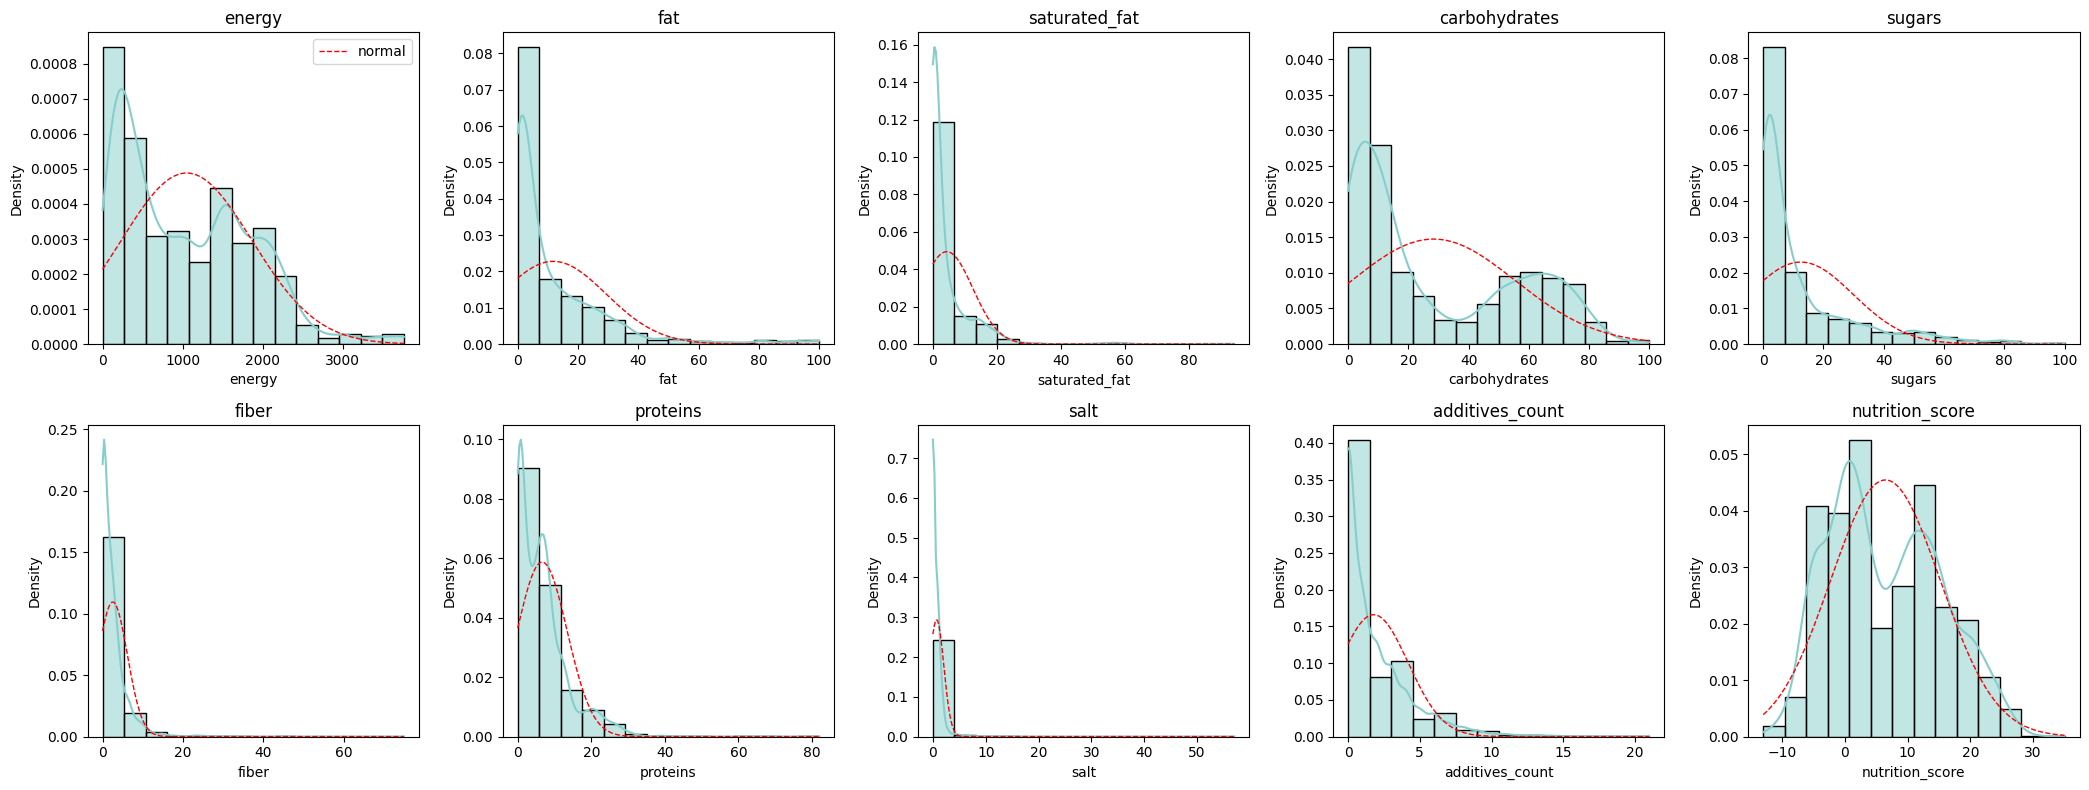

In [59]:
fig, axes = plt.subplots(2, 5, figsize=(21, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], stat='density', bins='sturges', color=COLOR, ax=ax, kde=True)
    x = np.linspace(df[c].min(), df[c].max(), 200)
    mu, sd = f_mean(df[c]), f_std(df[c]); ax.plot(x, np.exp(-(x - mu) ** 2 / (2 * sd ** 2)) / (sd * math.sqrt(2 * math.pi)), 'r--', lw=1, label='normal'); ax.set_title(c)
axes[0,0].legend(); plt.tight_layout(); plt.show()

**Kriteria penilaian:** simetris bila |skewness| < 0,5; miring kanan bila skewness > 0 (mean > median, ekor panjang di kanan); jumlah puncak dari histogram yang dihaluskan; "mendekati normal" bila |skewness| < 0,5 **dan** |excess kurtosis| < 1 serta kurva histogram mengikuti kurva normal (garis merah putus-putus).

**Kesimpulan (berdasarkan tabel & grafik di atas):**
- **fat, saturated_fat, sugars, fiber, proteins, salt, additives_count**: sangat **miring kanan**, 1 puncak di dekat nol (skewness 1,9 s.d. 18; mean > median; excess kurtosis positif besar = ekor berat). **Tidak normal.** `salt` dan `fiber` paling ekstrem karena hampir semua produk bernilai rendah dan sedikit produk sangat tinggi.
- **energy** dan **carbohydrates**: miring kanan ringan (skewness ≈ 0,65–0,69), **2 puncak** (bimodal: kelompok produk rendah-energi seperti minuman/buah-sayur vs. produk padat energi seperti sereal/camilan), excess kurtosis negatif (≈ datar). **Tidak normal** karena bimodal.
- **nutrition_score**: skewness 0,29 (hampir simetris), 1 puncak, namun excess kurtosis −0,84 (lebih datar dari normal). **Paling mendekati normal**, tetapi bukan normal sempurna (puncaknya lebih datar).
Alasan: bentuk histogram vs kurva normal, selisih mean–median, serta skewness/kurtosis dan jumlah puncak.

### 💡 Insight Soal 4 — Bentuk distribusi
- **Miring kanan, 1 puncak, tidak normal:** lemak, lemak jenuh, gula, serat, protein, garam, aditif (skewness 1,9–18,2; mean > median; excess kurtosis positif besar = ekor berat). Penyebabnya: mayoritas produk berkadar rendah, sedikit produk berkadar sangat tinggi.
- **Energi dan karbohidrat: 2 puncak (bimodal)**, skewness ringan (≈ 0,65–0,69), excess kurtosis negatif (energi −0,14; karbohidrat −1,09) — cerminan campuran produk rendah-energi (minuman, buah-sayur) dan padat-energi (sereal, camilan, minyak). Karena bimodal, **tidak normal**.
- **`nutrition_score` paling mendekati normal:** skewness 0,29 (simetris), 1 puncak, mean 6,46 ≈ median 5; namun excess kurtosis −0,84 (lebih datar dari normal).
- Konsekuensi: uji-t aman karena n besar (CLT), tetapi **uji variansi (5.4, 6.4) rentan** karena lemak jelas tidak normal.

## 6. Soal 5 — Uji Hipotesis Satu Sampel

In [60]:
def lapor(nama, stat, p, alpha=ALPHA):
    print(f'{nama}: statistik uji = {stat:.4f}, p-value = {p:.6g} -> ' + ('TOLAK H0' if p < alpha else 'GAGAL TOLAK H0'))

### 5.1 Rata-rata gula ≠ 12,5 g (uji-t dua sisi)
$H_0:\mu=12{,}5$ ; $H_1:\mu\neq12{,}5$. n besar → uji-t satu sampel (robust via CLT).

In [61]:
stat_uji_sukrosa, p = t_satu_sampel(df.sugars.values, 12.5, 'two')
print('rata-rata sampel =', round(f_mean(df.sugars), 4)); lapor('Gula', stat_uji_sukrosa, p)

rata-rata sampel = 12.4412
Gula: statistik uji = -0.2331, p-value = 0.815671 -> GAGAL TOLAK H0


### 5.2 Rata-rata garam < 1 g (uji-t sisi kiri)
$H_0:\mu=1$ ; $H_1:\mu<1$.

In [62]:
t, p = t_satu_sampel(df.salt.values, 1, 'less')
print('rata-rata sampel =', round(f_mean(df.salt), 4)); lapor('Garam', t, p)

rata-rata sampel = 0.7013
Garam: statistik uji = -15.1979, p-value = 2.82617e-51 -> TOLAK H0


### 5.3 Proporsi produk berminyak sawit < 10% (uji-z proporsi sisi kiri)
$H_0:p=0{,}10$ ; $H_1:p<0{,}10$. Syarat: $np_0$ dan $n(1-p_0)$ ≥ 10.

In [63]:
n = len(df); x = (df.palm_oil == 'Yes').sum(); print('proporsi sampel =', round(x/n, 4), '| n*p0 =', n*0.1)
z, p = z_prop_satu(x, n, 0.10, 'less'); lapor('Proporsi sawit', z, p)

proporsi sampel = 0.0748 | n*p0 = 475.8
Proporsi sawit: statistik uji = -5.7893, p-value = 3.53478e-09 -> TOLAK H0


### 5.4 Simpangan baku lemak *Sugary snacks* > 12 g (uji χ² sisi kanan)
$H_0:\sigma=12$ ; $H_1:\sigma>12$; $\chi^2=(n-1)s^2/\sigma_0^2$, db = n−1. Asumsi: normal (diberikan soal).

In [64]:
fat_ss = df.loc[df.food_group == 'Sugary snacks', 'fat']
chi2, p = chi2_var(fat_ss.values, 12, 'greater')
print(f'n = {len(fat_ss)}, s = {f_std(fat_ss):.4f}'); lapor('Simpangan baku lemak', chi2, p)

n = 816, s = 12.6585
Simpangan baku lemak: statistik uji = 906.9036, p-value = 0.0134706 -> TOLAK H0


### 💡 Insight Soal 5 — Uji satu sampel (α = 0,05)
- **5.1 Gula:** t = −0,233, p = 0,816 → **gagal tolak H₀**. Rata-rata gula 12,44 g ≈ klaim buku (12,5 g). Tetapi median hanya 4,53 g: angka 12,5 benar sebagai *rata-rata*, namun tidak menggambarkan produk tipikal; rata-ratanya didongkrak *Sugary snacks* (≈ 38 g) dan minuman (≈ 11,5 g).
- **5.2 Garam:** rata-rata 0,70 g, t = −15,2, p ≈ 10⁻⁵¹ → **tolak H₀**, rata-rata jelas di bawah 1 g. Catatan: Q3 = 1,0 g, sehingga sekitar seperempat produk masih ≥ 1 g; target rata-rata terpenuhi, tetapi tidak semua produk.
- **5.3 Sawit:** proporsi 7,48% (< 10%), z = −5,79, p ≈ 3,5×10⁻⁹ → **tolak H₀**; dugaan Bomori benar (uji eksak binomial memberi kesimpulan sama). Sawit ada pada sekitar 1 dari 13 produk.
- **5.4 Simpangan baku lemak Sugary snacks:** s = 12,66 > 12, χ² = 906,9, p = 0,0135 → **tolak H₀** pada α = 5%. Lemak camilan manis sedikit **lebih beragam** daripada klaim label, tetapi selisihnya kecil (≈ 5%) dan tidak signifikan pada α = 1%; hasil juga bergantung asumsi normal yang tidak terpenuhi.

## 7. Soal 6 — Uji Hipotesis Dua Sampel

### 6.1 Selisih rata-rata nutrition_score (sawit − tanpa sawit) > 8 (Welch, sisi kanan)
$H_0:\mu_1-\mu_2=8$ ; $H_1:\mu_1-\mu_2>8$. Variansi tidak diasumsikan sama (Welch), karena ukuran kelompok sangat timpang.

In [65]:
a = df.loc[df.palm_oil == 'Yes', 'nutrition_score']; b = df.loc[df.palm_oil == 'No', 'nutrition_score']
selisih_gizi_kelapa_sawit = f_mean(a) - f_mean(b)
print(f'n sawit={len(a)}, n non-sawit={len(b)}, selisih rata-rata = {selisih_gizi_kelapa_sawit:.4f}')
t, p, db = t_welch(a.values, b.values, 8, 'greater'); lapor('Selisih > 8', t, p)

n sawit=356, n non-sawit=4402, selisih rata-rata = 9.3690
Selisih > 8: statistik uji = 3.4822, p-value = 0.000273268 -> TOLAK H0


### 6.2 Rata-rata nutrition_score *Fish meat eggs* ≠ *Milk and dairy products* (Welch, dua sisi)

In [66]:
a = df.loc[df.food_group == 'Fish meat eggs', 'nutrition_score']; b = df.loc[df.food_group == 'Milk and dairy products', 'nutrition_score']
print(f'mean ikan/daging/telur = {f_mean(a):.4f}, mean susu = {f_mean(b):.4f}')
t, p, db = t_welch(a.values, b.values, 0, 'two'); lapor('Beda rata-rata', t, p)

mean ikan/daging/telur = 7.2145, mean susu = 7.0823
Beda rata-rata: statistik uji = 0.2526, p-value = 0.80068 -> GAGAL TOLAK H0


### 6.3 Proporsi produk beraditif: *Composite foods* > *Cereals and potatoes* (uji-z dua proporsi, sisi kanan)

In [67]:
g1 = df[df.food_group == 'Composite foods'].additives_count > 0; g2 = df[df.food_group == 'Cereals and potatoes'].additives_count > 0
print(f'p1 = {g1.sum()/len(g1):.4f} (n={len(g1)}), p2 = {g2.sum()/len(g2):.4f} (n={len(g2)})')
z, p = z_prop_dua(g1.sum(), len(g1), g2.sum(), len(g2), 'greater'); lapor('p1 > p2', z, p)

p1 = 0.6880 (n=609), p2 = 0.3910 (n=775)
p1 > p2: statistik uji = 10.9813, p-value = 2.35119e-28 -> TOLAK H0


### 6.4 Variansi lemak *Sugary snacks* = *Salty snacks* (uji-F dua sisi)
$H_0:\sigma_1^2=\sigma_2^2$ ; $F=s_1^2/s_2^2$, db = (n₁−1, n₂−1). Asumsi: normal (diberikan soal).

In [68]:
f1 = df.loc[df.food_group == 'Sugary snacks', 'fat']; f2 = df.loc[df.food_group == 'Salty snacks', 'fat']
F, p = f_var_test(f1.values, f2.values)
print(f'var sugary = {f_var(f1):.4f}, var salty = {f_var(f2):.4f}'); lapor('Uji F', F, p)

var sugary = 160.2382, var salty = 208.2974
Uji F: statistik uji = 0.7693, p-value = 0.0122885 -> TOLAK H0


### 💡 Insight Soal 6 — Uji dua sampel (α = 0,05)
- **6.1 Sawit vs non-sawit (skor gizi):** rata-rata 15,13 vs 5,76, selisih **9,37** > 8, t = 3,48, p = 0,0003 → **tolak H₀**. Produk bersawit secara signifikan lebih tidak sehat, dengan margin terhadap 8 poin yang tipis (≈ 1,4 poin). Ini asosiasi, bukan sebab-akibat: sawit terkonsentrasi pada *Sugary snacks* (23,5% produknya bersawit) dan *Cereals and potatoes* (10,1%), kelompok yang memang berskor tinggi.
- **6.2 Fish meat eggs vs Milk and dairy:** 7,21 vs 7,08, t = 0,253, p = 0,80 → **gagal tolak H₀**. Dari sisi skor gizi tidak ada perbedaan; keduanya setara. (Pertimbangan lain: ikan/daging/telur bergaram lebih tinggi, rata-rata ≈ 1,80 g vs 0,58 g susu.)
- **6.3 Aditif:** produk beraditif 68,8% (*Composite foods*) vs 39,1% (*Cereals and potatoes*), z = 10,98, p ≈ 10⁻²⁸ → **tolak H₀**. Dugaan Bomori terbukti sangat kuat: makanan siap saji jauh lebih sering mengandung bahan tambahan (selisih ≈ 30 poin persen).
- **6.4 Variansi lemak:** Sugary snacks 160,2 vs Salty snacks 208,3, F = 0,769, p = 0,0123 → **tolak H₀**. Kadar lemak **Sugary snacks lebih konsisten** (sd ≈ 12,7 vs 14,4), jadi lebih cocok untuk mesin Bomori yang rewel. Syarat normalitas tidak terpenuhi, sehingga hasilnya sebaiknya dianggap indikatif.

## 8. Pembanding: Fungsi Buatan vs Library

In [69]:
# Bagian terpisah: fungsi library HANYA untuk verifikasi
lib = pd.DataFrame({'mean': df[num_cols].mean(), 'median': df[num_cols].median(), 'modus': df[num_cols].mode().iloc[0],
    'std (sampel)': df[num_cols].std(), 'var (sampel)': df[num_cols].var(), 'Q1': df[num_cols].quantile(.25),
    'Q3': df[num_cols].quantile(.75), 'skewness': df[num_cols].skew(), 'excess kurtosis': df[num_cols].kurt()})
print('Selisih absolut maksimum fungsi buatan vs pandas (per statistik):'); display((desc_tbl[lib.columns] - lib).abs().max())
for c in cat_cols:
    assert (f_freq(df[c]).frekuensi.sort_index() == df[c].value_counts().sort_index()).all()
print('Frekuensi kategori sama dengan value_counts: OK')
pa = df.loc[df.palm_oil == 'Yes', 'nutrition_score'].values; pb = df.loc[df.palm_oil == 'No', 'nutrition_score'].values
fg = lambda g: df.loc[df.food_group == g, 'nutrition_score'].values
cek = [('5.1', t_satu_sampel(df.sugars.values, 12.5, 'two'), stats.ttest_1samp(df.sugars, 12.5)),
       ('5.2', t_satu_sampel(df.salt.values, 1, 'less'), stats.ttest_1samp(df.salt, 1, alternative='less')),
       ('6.1', t_welch(pa, pb, 8, 'greater')[:2], stats.ttest_ind(pa - 8, pb, equal_var=False, alternative='greater')),
       ('6.2', t_welch(fg('Fish meat eggs'), fg('Milk and dairy products'), 0, 'two')[:2], stats.ttest_ind(fg('Fish meat eggs'), fg('Milk and dairy products'), equal_var=False))]
for k, own, lb in cek: print(k, 'buatan =', tuple(round(float(v), 6) for v in own), '| scipy =', (round(lb.statistic, 6), round(lb.pvalue, 6)))
nx = int((df.palm_oil == 'Yes').sum())   # 5.3: z-aproksimasi (buatan) vs uji binomial eksak
print('5.3 p z-aproksimasi =', z_prop_satu(nx, len(df), .1, 'less')[1], '| binomtest eksak =', stats.binomtest(nx, len(df), .1, alternative='less').pvalue)

Selisih absolut maksimum fungsi buatan vs pandas (per statistik):


mean              0.0000
median            0.0000
modus             0.0000
std (sampel)      0.0000
var (sampel)      0.0000
Q1                0.0000
Q3                0.0000
skewness          0.0000
excess kurtosis   0.0000
dtype: float64

Frekuensi kategori sama dengan value_counts: OK
5.1 buatan = (-0.233129, 0.815671) | scipy = (np.float64(-0.233129), np.float64(0.815671))
5.2 buatan = (-15.19792, 0.0) | scipy = (np.float64(-15.19792), np.float64(0.0))
6.1 buatan = (3.482188, 0.000273) | scipy = (np.float64(3.482188), np.float64(0.000273))
6.2 buatan = (0.252573, 0.80068) | scipy = (np.float64(0.252573), np.float64(0.80068))
5.3 p z-aproksimasi = 3.5347782849268824e-09 | binomtest eksak = 9.895028451374744e-10


## 9. Ringkasan Insight

In [70]:
print('stat_uji_sukrosa =', stat_uji_sukrosa); print('selisih_gizi_kelapa_sawit =', selisih_gizi_kelapa_sawit)

stat_uji_sukrosa = -0.23312911883795429
selisih_gizi_kelapa_sawit = 9.368960227475764


### 💡 Insight keseluruhan
1. **Rata-rata menyesatkan pada data gizi pangan:** distribusi miring kanan, jadi laporkan median dan kuartil bersama mean.
2. **Kelompok pangan adalah penggerak utama gizi:** rata-rata `nutrition_score` terbaik *Fruits and vegetables* (−3,75) dan *Cereals and potatoes* (0,53); terburuk *Sugary snacks* (16,38), *Fat and sauces* (10,98), dan *Salty snacks* (10,68). Skor ini konsisten dengan Nutri-Score: A −4,1 → B 0,8 → C 5,9 → D 13,1 → E 19,3 (naik monoton, lebih tinggi = lebih tidak sehat).
3. **Minyak sawit adalah penanda produk olahan tinggi gula/lemak**, bukan faktor yang terbukti menyebabkan skor buruk.
4. **Bahan tambahan** terkonsentrasi pada makanan siap saji, sedangkan garam rata-rata sudah di bawah ambang 1 g.
5. Keputusan statistik paling kokoh: 5.2, 5.3, 6.1, 6.3 (p sangat kecil, tidak bergantung normalitas). Paling rapuh: 5.4 dan 6.4 (p ≈ 0,01 dan bergantung normalitas).
Peringatan metodologis: (i) data miring kanan sehingga uji-t mengandalkan CLT (n besar), (ii) uji variansi 5.4 dan 6.4 sensitif terhadap pelanggaran normalitas — hasilnya perlu dibaca hati-hati karena lemak camilan tidak normal, (iii) uji-uji dilakukan terpisah tanpa koreksi perbandingan ganda.